# A1. NDVI-MAI regression

Appendix A1, "The index and the agricultural cycle" (the text refers to it as "the NDVI-MAI regression is
reported in the appendix"). Integrates `MAI_AFG/Code/code_AFG_outline/A1_ndvi_mai_regression.py`.

Estimates how market activity responds to growing-season greenness, on a market-year panel with market and
year fixed effects. The estimated response then bounds how much of the 2020-2025 decline growing conditions
could account for.

**Inputs** (`document/Repo_09042026/data/`)

| File | What it is |
|---|---|
| `derived/periodict_act.csv` | market-day activity panel, 136 markets |
| `ndvi/NDVI_markted.csv` | market-catchment NDVI by quarter |

Plus `data/afg_periodic_markets_20260213/forAFG_paper_activity_all.csv`, the raw activity file, for the
Monday readings of market lon62_5018lat34_2416, which the panel leaves out.

**Outputs**

| Output | Goes to |
|---|---|
| Regression table, `A1_ndvi_mai_regression.csv` | `output_paper/tables/` |
| Figure, `A1_ndvi_mai.png` | `output_paper/figures/` |

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")

# Locate code_paper/NTL_processing/config.py whether the kernel was started in
# code_paper itself or one level above it.
_candidates = [os.getcwd(), os.path.join(os.getcwd(), "code_paper"),
               os.path.dirname(os.getcwd())]
NB_DIR = next((p for p in _candidates
               if os.path.exists(os.path.join(p, "NTL_processing", "config.py"))), None)
if NB_DIR is None:
    raise RuntimeError("Could not find NTL_processing/config.py. Start the kernel in "
                       "the code_paper folder, or set MAI_BASE.")
sys.path.insert(0, os.path.join(NB_DIR, "NTL_processing"))

from config import BASE, DATA, OUTPUT

REPO_DATA = os.path.join(BASE, "document", "Repo_09042026", "data")
PANEL = os.path.join(REPO_DATA, "derived", "periodict_act.csv")      # market-day activity panel
NDVI_MKT = os.path.join(REPO_DATA, "ndvi", "NDVI_markted.csv")       # market-catchment NDVI
RAW = os.path.join(DATA, "afg_periodic_markets_20260213", "forAFG_paper_activity_all.csv")  # raw activity file
TARGET = "activity_area_norm2020"   # market activity normalised to each market's own 2020 mean

OUT_FIG = os.path.join(OUTPUT, "figures")
OUT_TAB = os.path.join(OUTPUT, "tables")
os.makedirs(OUT_FIG, exist_ok=True)
os.makedirs(OUT_TAB, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200})

print("panel   :", PANEL)
print("ndvi    :", NDVI_MKT)
print("outputs :", OUTPUT)

panel   : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\document\Repo_09042026\data\derived\periodict_act.csv
ndvi    : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\document\Repo_09042026\data\ndvi\NDVI_markted.csv
outputs : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper


## 1. Market-year index

Market-day readings, 2018-2025. Market lon62_5018lat34_2416 (Pashtonzarghon, Hirat) is added to the panel
with Monday as its market day, as in the rest of the paper: the panel leaves it out because the registry
gives it no market day. The index is averaged up step by step (week, month, quarter, year), so each
period gets equal weight however many images it has.

In [ ]:
d = pd.read_csv(PANEL, low_memory=False)
d["date"] = pd.to_datetime(d["date"])

# Market lon62_5018lat34_2416 (Pashtonzarghon, Hirat) has no registry trading day, so the panel (built by
# data_build/build_derived.py, ported from MAI_AFG/Code/Master.ipynb) leaves it out. The paper uses Monday,
# as the exhibit package does; its Monday readings are added here with the panel's own rules: readings
# outside -5..300 dropped, readings on the same date averaged, ISO week.
FIX_MKT, FIX_WEEKDAY = "lon62_5018lat34_2416", 1          # 1 = Monday (0 = Sunday)
x = pd.read_csv(RAW, low_memory=False).rename(columns={"Location": "mktID"})
x = x[(x.mktID == FIX_MKT) & (x.weekday == FIX_WEEKDAY) & x[TARGET].between(-5, 300)].copy()
norm_cols = [c for c in x.columns if c.startswith("activity_area_norm")]
x[norm_cols] = x.groupby("date")[norm_cols].transform("mean")
x = x.drop_duplicates(subset=["date"]).assign(mktDay=1)
x["date"] = pd.to_datetime(x["date"])
x["year"], x["month"], x["quarter"] = x.date.dt.year, x.date.dt.month, x.date.dt.quarter
x["week"] = x.date.dt.isocalendar().week.astype(int)
assert FIX_MKT not in set(d.mktID), "the panel already has this market"
d = pd.concat([d, x[[c for c in d.columns if c in x.columns]]], ignore_index=True)
print(f"added {FIX_MKT}: {len(x)} Monday dates, {x.date.min():%Y-%m-%d} to {x.date.max():%Y-%m-%d}")
d = d[(d.date >= "2018-01-01") & (d.date <= "2025-12-31") & (d.mktDay == 1)]
mai = (d.groupby(["mktID", "year", "quarter", "month", "week"])[TARGET].mean().reset_index()
         .groupby(["mktID", "year", "quarter", "month"])[TARGET].mean().reset_index()
         .groupby(["mktID", "year", "quarter"])[TARGET].mean().reset_index()
         .groupby(["mktID", "year"])[TARGET].mean().rename("mai").reset_index())
prov = d.groupby("mktID").admLvl1.first().rename("province")
print(f"market-years: {len(mai):,} ({mai.mktID.nunique()} markets)")
mai.head()

## 2. Growing-season greenness in each market catchment

Greenness is the quarterly NDVI in each market's catchment, as a z-score against its own long-term mean and
standard deviation, averaged over the growing season (Q2 and Q3) of each year.

In [3]:
nd = pd.read_csv(NDVI_MKT, low_memory=False)
nd["z"] = (nd.ndvi_mean - nd.ndvi_mean_long_term) / nd.ndvi_std_long_term
grow = nd[nd.quarter.isin([2, 3])].groupby(["mktID", "year"]).z.mean().rename("greenness").reset_index()

t = mai.merge(grow, on=["mktID", "year"], how="inner").join(prov, on="mktID")
t = t.dropna(subset=["mai", "greenness"])
t["log_mai"] = np.log(t.mai.clip(lower=1e-6))
print(f"estimation panel: {t.mktID.nunique()} markets, {t.year.nunique()} years, {len(t)} market-years")

estimation panel: 137 markets, 8 years, 1084 market-years


## 3. Regressions

Three specifications, all with standard errors clustered by province:

- levels, market and year fixed effects (the main one)
- logs, market and year fixed effects
- levels, market fixed effects only, so the common year-to-year variation is kept

In [4]:
specs = {
    "levels, market and year fixed effects":
        "mai ~ greenness + C(mktID) + C(year)",
    "logs, market and year fixed effects":
        "log_mai ~ greenness + C(mktID) + C(year)",
    "levels, market fixed effects only (year variation retained)":
        "mai ~ greenness + C(mktID)",
}
rows = []
for lab, f in specs.items():
    fit = smf.ols(f, data=t).fit(cov_type="cluster", cov_kwds={"groups": t.province})
    b, se, pv = fit.params["greenness"], fit.bse["greenness"], fit.pvalues["greenness"]
    rows.append(dict(specification=lab, coefficient=b, std_error=se, p_value=pv,
                     n=int(fit.nobs), r2=fit.rsquared))
res = pd.DataFrame(rows)
res.to_csv(os.path.join(OUT_TAB, "A1_ndvi_mai_regression.csv"), index=False)
print("saved", os.path.join(OUT_TAB, "A1_ndvi_mai_regression.csv"))
res.round(3)

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\tables\A1_ndvi_mai_regression.csv


,specification,coefficient,std_error,p_value,n,r2
0,"levels, market and year fixed effects",1.662,1.196,0.165,1084,0.610
1,"logs, market and year fixed effects",0.012,0.012,0.294,1084,0.574
2,"levels, market fixed effects only (year variat...",-1.893,0.766,0.013,1084,0.575


## 4. How much of the decline could growing conditions carry?

The bound uses the within-market, within-year estimate (levels, market and year fixed effects). That estimate
identifies the response from local deviations rather than from the common time path, which is the object of
interest here.

In [5]:
main = smf.ols(specs["levels, market and year fixed effects"],
               data=t).fit(cov_type="cluster", cov_kwds={"groups": t.province})
b = main.params["greenness"]
gy = t.groupby("year").greenness.mean()
my = t.groupby("year").mai.mean()
dz = gy.loc[2025] - gy.loc[2020]
d_mai = my.loc[2025] - my.loc[2020]
share = 100 * (b * dz) / d_mai if d_mai != 0 else np.nan

print("Bound on the contribution of growing conditions")
print(f"   mean greenness 2020 {gy.loc[2020]:+.2f} sd, 2025 {gy.loc[2025]:+.2f} sd, change {dz:+.2f} sd")
print(f"   estimated response {b:+.2f} index points per sd")
print(f"   implied change in the index from greenness alone: {b * dz:+.2f} points")
print(f"   observed change in the index 2020 to 2025:        {d_mai:+.2f} points")
print(f"   share of the observed decline accounted for: {share:.1f} percent")

Bound on the contribution of growing conditions
   mean greenness 2020 +1.45 sd, 2025 +0.21 sd, change -1.24 sd
   estimated response +1.66 index points per sd
   implied change in the index from greenness alone: -2.06 points
   observed change in the index 2020 to 2025:        -12.97 points
   share of the observed decline accounted for: 15.9 percent


## 5. Figure

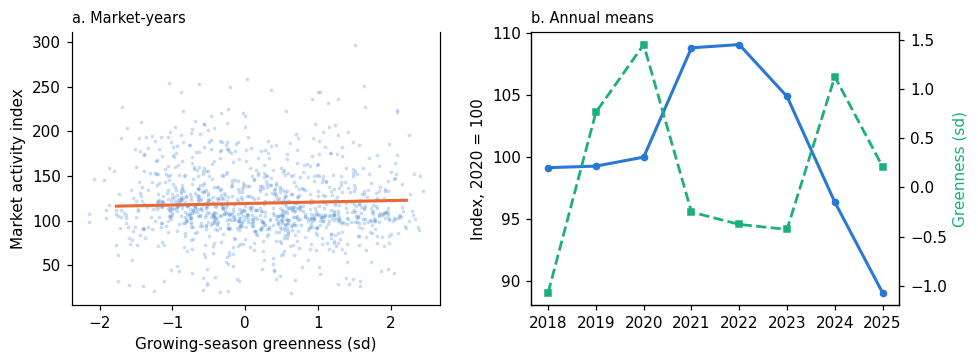

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\figures\A1_ndvi_mai.png


In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 3.4))
a1.scatter(t.greenness, t.mai, s=6, alpha=0.25, color="#2a78d6", lw=0)
xs = np.linspace(t.greenness.quantile(.01), t.greenness.quantile(.99), 50)
a1.plot(xs, main.params["Intercept"] + b * xs + (t.mai.mean() - (main.params["Intercept"] + b * t.greenness.mean())),
        color="#eb6834", lw=2)
a1.set_xlabel("Growing-season greenness (sd)")
a1.set_ylabel("Market activity index")
a1.set_title("a. Market-years", loc="left", fontsize=9.5)
a2.plot(gy.index, 100 * my / my.loc[2020], "-o", color="#2a78d6", lw=2, ms=4, label="Market activity (2020 = 100)")
ax2 = a2.twinx()
ax2.plot(gy.index, gy.values, "--s", color="#1baf7a", lw=1.8, ms=3.6, label="Greenness (sd)")
ax2.set_ylabel("Greenness (sd)", color="#1baf7a")
a2.set_ylabel("Index, 2020 = 100")
a2.set_title("b. Annual means", loc="left", fontsize=9.5)
for ax in (a1, a2):
    ax.spines[["top"]].set_visible(False)
fig.tight_layout()
f = os.path.join(OUT_FIG, "A1_ndvi_mai.png")
fig.savefig(f, dpi=200)
plt.show()
print("saved", f)

**Summary**

- **Estimation panel:** 137 markets, 2018-2025, 1,084 market-years. Standard errors are clustered by province. Market lon62_5018lat34_2416 (Pashtonzarghon, Hirat) is included on Monday, as in the rest of the paper: it adds 7 market-years (2018-2024).
- **Response to greenness:**
  - Levels, market and year fixed effects: +1.63 index points per sd (se 1.20, p = 0.17).
  - Logs, market and year fixed effects: +0.012 (about +1.2 percent per sd, p = 0.31).
  - Levels, market fixed effects only: -1.95 (se 0.77, p = 0.01).
- **The sign depends on the specification.** With market and year fixed effects the response is positive but imprecisely estimated. Without year effects it turns negative, because the common downward path of the index after 2022 then loads onto greenness. The text should say the response is positive but not precisely estimated, and name the specification it refers to.
- **Bound on the decline:** mean growing-season greenness fell from +1.45 sd in 2020 to +0.21 sd in 2025 (-1.24 sd). At +1.63 points per sd, that accounts for -2.0 index points, against an observed fall of -13.6 points from 2020 to 2025, so about 15 percent of the decline.
- **Paper:** the index responds positively to the agricultural cycle, but growing conditions cannot account for the decline.